# 01 · Build face-quality labels (Đức Mạnh)

**Goal.** Make a training set for a face-quality model that predicts how useful a face crop is *to the team's own
recogniser* (`ml/face_recognition/face_recognition.pt`, v1, triplet + cosine).

**Recipe.**
1. Sample identities from the Kaggle `classification_data/train_data` split (pinned archive, SHA-256 checked).
2. For every clean image make damaged copies: 9 damage types (blur, motion blur, noise, JPEG, downscale, dark, bright,
   occlusion, pose warp), each at a random level in (0, 1].
3. Embed every crop (clean and damaged) with the team recogniser.
4. **Label** = cosine similarity between a crop's embedding and the mean embedding of the *other* clean images of the
   same person (leave-one-out, so a clean image is never compared with itself). High = the recogniser still finds
   this person in this crop.
5. Split train / validation **by identity**, so no person is in both.

No hand labelling. Runs on CPU (the recogniser is needed here); the outputs go to Drive for `02_train_quality.ipynb`.

In [1]:
import csv, hashlib, io, json, sys, time, zipfile
from collections import Counter, defaultdict
from pathlib import Path

import cv2
import numpy as np
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt

REPO = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / ".agents").is_dir())
sys.path.insert(0, str(REPO / "ml" / "face_recognition"))
sys.path.insert(0, str(REPO / "ml" / "face_quality"))
import infer as recogniser                 # team recogniser (Thuận Minh)
from damage import DAMAGES, damage         # damage functions shared with training and evaluation

RAW = REPO / "data" / "raw" / "face_quality"
ARCHIVE = RAW / "archive.zip"
ARCHIVE_SHA256 = "ec28aa0128101beecf7b8aa08d0bb0f7e0d49ce39b2929c9b563c0dc8b116f60"   # same pin as ml/face_recognition
PREFIX = "11-785-fall-20-homework-2-part-2-2/classification_data/train_data/"
OUT = RAW / "labels"
OUT.mkdir(parents=True, exist_ok=True)

SEED = 30082
N_IDENTITIES = 800          # identities sampled from train_data (4000 available)
PER_IDENTITY = 10           # clean images per identity
COPIES = 2                  # damaged copies per clean image
VAL_SHARE = 0.2             # share of identities held out for validation
rng = np.random.default_rng(SEED)
print("repo:", REPO)
print("damage types:", list(DAMAGES))

repo: C:\Users\Admin\Documents\GitHub\Facial_Recognition_TeamProject
damage types: ['blur', 'motion', 'noise', 'jpeg', 'downscale', 'dark', 'bright', 'occlusion', 'pose']


## 1. Check the archive and sample identities

In [2]:
if not ARCHIVE.is_file():
    raise SystemExit(f"Download the Kaggle archive to {ARCHIVE} first (see README, 'Data').")
h = hashlib.sha256()
with ARCHIVE.open("rb") as f:
    for chunk in iter(lambda: f.read(1 << 22), b""):
        h.update(chunk)
assert h.hexdigest() == ARCHIVE_SHA256, "archive does not match the pinned version"
print("archive SHA-256 OK")

zf = zipfile.ZipFile(ARCHIVE)
by_id = defaultdict(list)
for name in zf.namelist():
    if name.startswith(PREFIX) and name.endswith(".jpg"):
        by_id[name[len(PREFIX):].split("/")[0]].append(name)
eligible = sorted(k for k, v in by_id.items() if len(v) >= PER_IDENTITY)
print(f"{len(by_id)} identities in train_data, {len(eligible)} with >= {PER_IDENTITY} images")

chosen = sorted(rng.choice(eligible, N_IDENTITIES, replace=False).tolist())
n_val = int(round(N_IDENTITIES * VAL_SHARE))
val_ids = set(rng.choice(chosen, n_val, replace=False).tolist())
files = [(i, f) for i in chosen for f in sorted(rng.choice(sorted(by_id[i]), PER_IDENTITY, replace=False).tolist())]

def read(name):
    return cv2.imdecode(np.frombuffer(zf.read(name), np.uint8), cv2.IMREAD_COLOR)

clean = np.stack([read(f) for _, f in files])
print("clean images:", clean.shape, clean.dtype, f"| train ids {N_IDENTITIES - n_val}, val ids {n_val}")

archive SHA-256 OK


4000 identities in train_data, 4000 with >= 10 images


clean images: (8000, 64, 64, 3) uint8 | train ids 640, val ids 160


## 2. Damaged copies

Each copy gets one damage type (uniform over the 9) and a level drawn uniformly from (0, 1].

all crops: (24000, 64, 64, 3) | per damage type: {'clean': 8000, np.str_('dark'): 1816, np.str_('occlusion'): 1706, np.str_('blur'): 1750, np.str_('bright'): 1835, np.str_('downscale'): 1789, np.str_('noise'): 1784, np.str_('motion'): 1808, np.str_('pose'): 1712, np.str_('jpeg'): 1800}


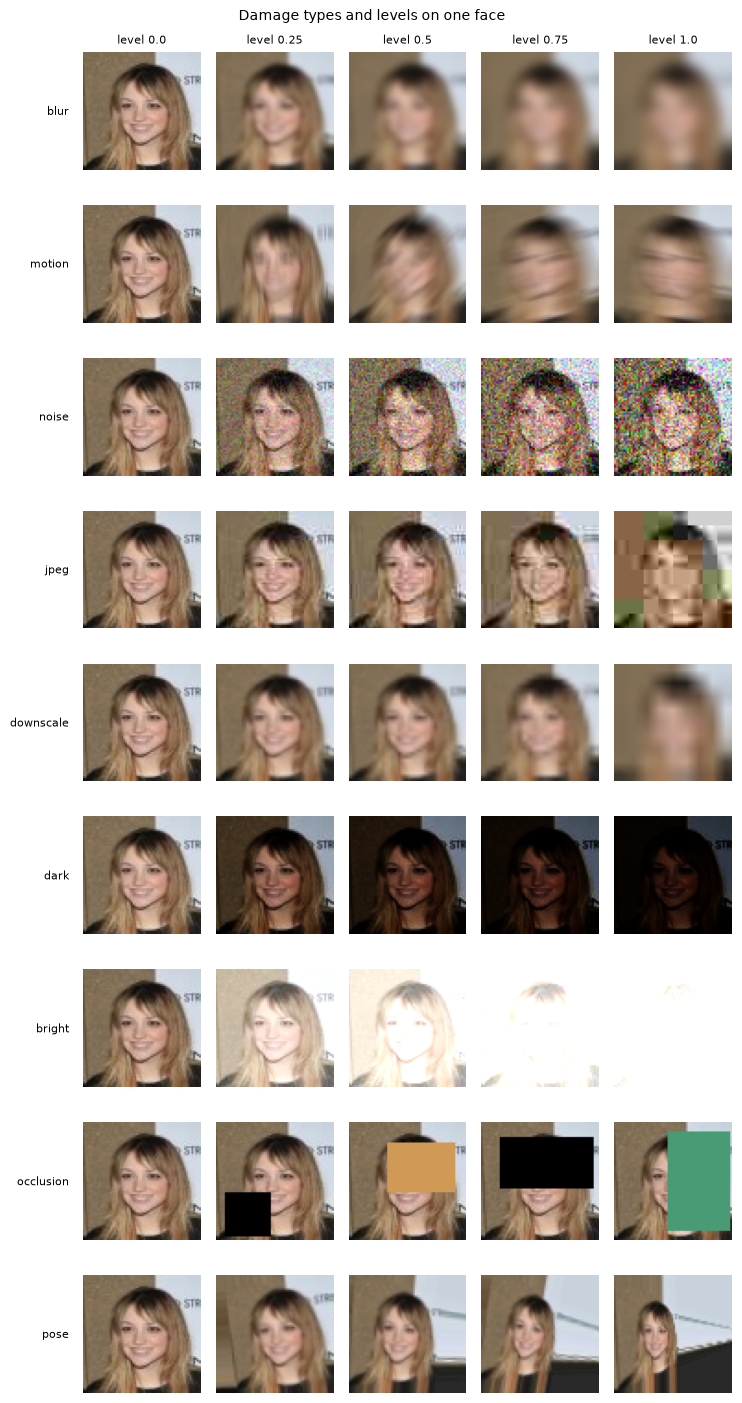

In [3]:
rows, images = [], []
for k, (ident, src) in enumerate(files):
    split = "val" if ident in val_ids else "train"
    rows.append(dict(identity=ident, source=src.split("/")[-1], damage="clean", level=0.0, split=split, clean_index=k))
    images.append(clean[k])
    for _ in range(COPIES):
        kind = rng.choice(list(DAMAGES))
        level = float(rng.uniform(0.05, 1.0))
        images.append(damage(clean[k], kind, level, rng))
        rows.append(dict(identity=ident, source=src.split("/")[-1], damage=kind, level=round(level, 4), split=split,
                         clean_index=k))
images = np.stack(images)
print("all crops:", images.shape, "| per damage type:", dict(Counter(r["damage"] for r in rows)))

fig, axes = plt.subplots(len(DAMAGES), 5, figsize=(7.5, 1.6 * len(DAMAGES)))
base = clean[0]
for r, kind in enumerate(DAMAGES):
    for c, level in enumerate((0.0, 0.25, 0.5, 0.75, 1.0)):
        img = base if level == 0 else damage(base, kind, level, np.random.default_rng(c))
        axes[r, c].imshow(img[:, :, ::-1]); axes[r, c].axis("off")
        if r == 0: axes[r, c].set_title(f"level {level}", fontsize=8)
    axes[r, 0].text(-8, 32, kind, ha="right", va="center", fontsize=8)
plt.suptitle("Damage types and levels on one face", fontsize=10); plt.tight_layout(); plt.show()

## 3. Embed with the team recogniser

Same preprocessing as `ml/face_recognition/infer.py::embed`, batched.

In [4]:
st = recogniser._load()
print("recogniser input", st["size"], "on", st["device"])

def embed_batch(bgr):
    x = torch.from_numpy(np.ascontiguousarray(bgr[..., ::-1])).permute(0, 3, 1, 2).float().to(st["device"]) / 255
    x = F.interpolate(x, size=st["size"], mode="bilinear", align_corners=False, antialias=True)
    with torch.inference_mode():
        return st["model"](((x - st["mean"]) / st["std"]).contiguous()).cpu().numpy().astype(np.float32)

t0 = time.time()
emb = np.concatenate([embed_batch(images[i:i + 256]) for i in range(0, len(images), 256)])
print(f"{len(emb)} embeddings in {time.time() - t0:.0f} s")
# the batched path must give the same vectors as the official embed()
assert np.allclose(emb[0], recogniser.embed(images[0]), atol=1e-4)

recogniser input (128, 128) on cpu


24000 embeddings in 220 s


## 4. Labels: cosine to the leave-one-out mean of the person's clean images

In [5]:
ident = np.array([r["identity"] for r in rows])
is_clean = np.array([r["damage"] == "clean" for r in rows])
cidx = np.array([r["clean_index"] for r in rows])
clean_emb = np.zeros((len(files), emb.shape[1]), np.float32)
clean_emb[cidx[is_clean]] = emb[is_clean]
groups = defaultdict(list)
for k, (i, _) in enumerate(files):
    groups[i].append(k)

sim = np.empty(len(rows), np.float32)
for i, ks in groups.items():
    total = clean_emb[ks].sum(0)
    for k in ks:
        ref = (total - clean_emb[k]) / (len(ks) - 1)        # mean of the OTHER clean images
        ref /= np.linalg.norm(ref)
        sel = np.where(cidx == k)[0]
        sim[sel] = emb[sel] @ ref

lo, hi = np.percentile(sim, [1, 99])
label = np.clip((sim - lo) / (hi - lo), 0, 1)
print(f"cosine: mean {sim.mean():.3f}, 1st pct {lo:.3f}, 99th pct {hi:.3f}  -> label = (cos - p1) / (p99 - p1), clipped")
print(f"clean mean label {label[is_clean].mean():.3f}, damaged mean label {label[~is_clean].mean():.3f}")

cosine: mean 0.686, 1st pct 0.358, 99th pct 0.901  -> label = (cos - p1) / (p99 - p1), clipped
clean mean label 0.769, damaged mean label 0.520


## 5. Checks: labels must fall as damage grows

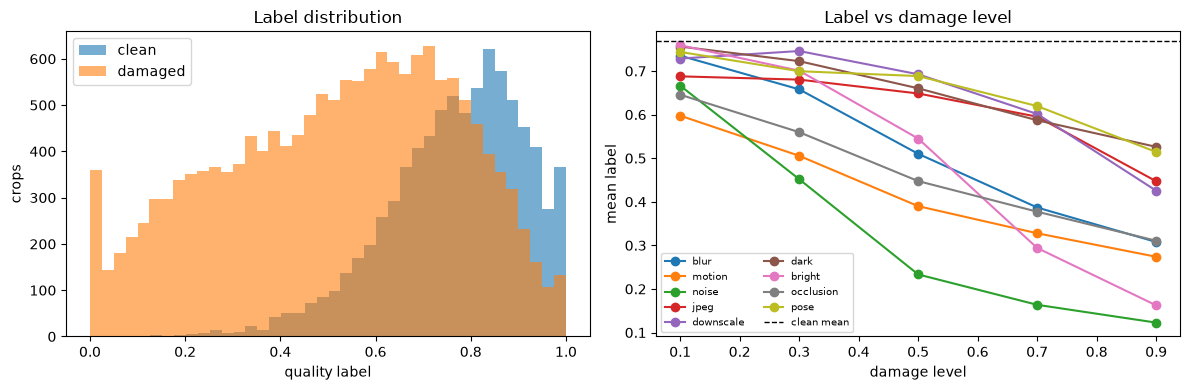

  blur       n= 1750  mean label 0.509  Spearman(level, label) -0.692
  motion     n= 1808  mean label 0.409  Spearman(level, label) -0.546
  noise      n= 1784  mean label 0.299  Spearman(level, label) -0.727
  jpeg       n= 1800  mean label 0.610  Spearman(level, label) -0.438
  downscale  n= 1789  mean label 0.634  Spearman(level, label) -0.536
  dark       n= 1816  mean label 0.642  Spearman(level, label) -0.434
  bright     n= 1835  mean label 0.472  Spearman(level, label) -0.817
  occlusion  n= 1706  mean label 0.460  Spearman(level, label) -0.544
  pose       n= 1712  mean label 0.650  Spearman(level, label) -0.428


In [6]:
levels = np.array([r["level"] for r in rows]); kinds = np.array([r["damage"] for r in rows])
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].hist(label[is_clean], 40, alpha=.6, label="clean"); ax[0].hist(label[~is_clean], 40, alpha=.6, label="damaged")
ax[0].set_xlabel("quality label"); ax[0].set_ylabel("crops"); ax[0].legend(); ax[0].set_title("Label distribution")
bins = np.linspace(0, 1, 6)
for kind in DAMAGES:
    m = kinds == kind
    centre = [(a + b) / 2 for a, b in zip(bins[:-1], bins[1:])]
    means = [label[m & (levels > a) & (levels <= b)].mean() for a, b in zip(bins[:-1], bins[1:])]
    ax[1].plot(centre, means, marker="o", label=kind)
ax[1].axhline(label[is_clean].mean(), color="k", ls="--", lw=1, label="clean mean")
ax[1].set_xlabel("damage level"); ax[1].set_ylabel("mean label"); ax[1].set_title("Label vs damage level")
ax[1].legend(fontsize=7, ncol=2); plt.tight_layout(); plt.show()

summary = {kind: dict(n=int((kinds == kind).sum()),
                      mean_label=float(label[kinds == kind].mean()),
                      spearman_level=float(np.corrcoef(np.argsort(np.argsort(levels[kinds == kind])),
                                                       np.argsort(np.argsort(label[kinds == kind])))[0, 1]))
           for kind in DAMAGES}
for k, v in summary.items():
    print(f"  {k:10s} n={v['n']:5d}  mean label {v['mean_label']:.3f}  Spearman(level, label) {v['spearman_level']:+.3f}")

## 6. Examples: lowest and highest labels

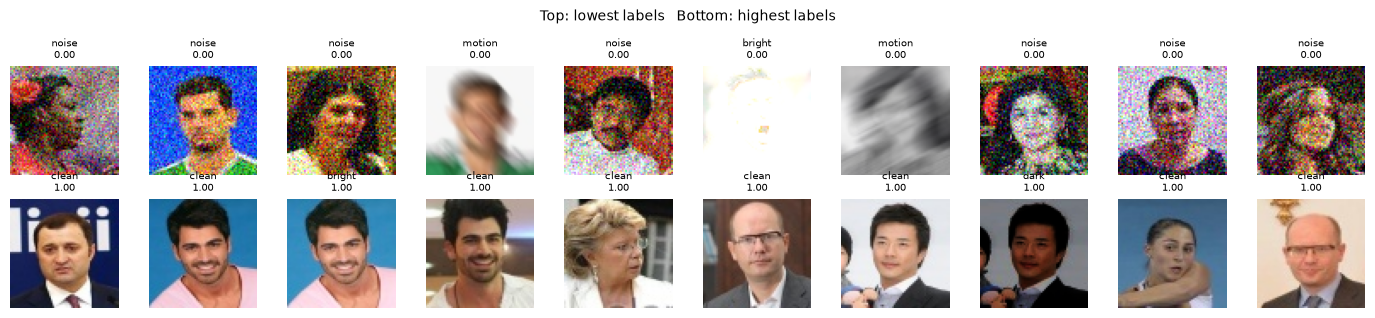

In [7]:
order = np.argsort(label)
fig, axes = plt.subplots(2, 10, figsize=(14, 3.2))
for c, k in enumerate(np.r_[order[:10], order[-10:]]):
    a = axes[c // 10, c % 10]; a.imshow(images[k][:, :, ::-1]); a.axis("off")
    a.set_title(f"{kinds[k]}\n{label[k]:.2f}", fontsize=7)
plt.suptitle("Top: lowest labels   Bottom: highest labels", fontsize=10); plt.tight_layout(); plt.show()

## 7. Save (upload `labels/` to Drive for notebook 02)

In [8]:
for r, s, l in zip(rows, sim, label):
    r["cosine"] = round(float(s), 5); r["label"] = round(float(l), 5)
np.save(OUT / "images.npy", images)
np.save(OUT / "embeddings.npy", emb)
with (OUT / "labels.csv").open("w", newline="", encoding="utf-8") as f:
    w = csv.DictWriter(f, fieldnames=list(rows[0])); w.writeheader(); w.writerows(rows)
meta = dict(seed=SEED, identities=N_IDENTITIES, per_identity=PER_IDENTITY, copies=COPIES,
            val_identities=n_val, crops=len(rows), image_shape=list(images.shape[1:]),
            label_rule="(cos - p1) / (p99 - p1), clipped to [0, 1]; cos to leave-one-out mean of clean images",
            cosine_p1=float(lo), cosine_p99=float(hi), damages=list(DAMAGES),
            recogniser="ml/face_recognition/face_recognition.pt",
            recogniser_version=json.loads((REPO / "ml/model_versions.json").read_text(encoding="utf-8"))["face_recognition"]["version"],
            archive_sha256=ARCHIVE_SHA256, per_damage=summary)
(OUT / "meta.json").write_text(json.dumps(meta, indent=1), encoding="utf-8")
for p in sorted(OUT.iterdir()):
    print(f"  {p.name:16s} {p.stat().st_size / 1e6:7.1f} MB")

  embeddings.npy      49.2 MB
  images.npy         294.9 MB
  labels.csv           1.4 MB
  meta.json            0.0 MB
